# 9-2-1 Φ8 — phage genome analysis ｜ 噬菌體基因體分析

**What / 內容:** basic genome information, the most similar known phage (NCBI, nucleotide + protein
level), and — in the final section — finding this genome's receptor-binding proteins (RBPs) and
checking whether it is catalogued in **PhaRBP** (`pharbp.ugent.be`).

基本基因體資訊、最相似的已知噬菌體（NCBI，核酸 + 蛋白質層級），最後一節找出本基因體的受體結合蛋白（RBP）
並在 **PhaRBP** 資料庫中查詢本噬菌體是否已被收錄。

---
**Genome used ｜ 使用的基因體:** our SPAdes assembly `NODE_13` (**62,338 bp**). It is the same molecule
as the PI group's canonical assembly (`PI_Phage_Assembly_Version1.fa`, **62,416 bp**) but
reverse-complemented + rotated, with one copy of the **77 bp Direct Terminal Repeat (DTR)** trimmed by
SPAdes. Annotation (pharokka) and the RBP analysis were done on our coordinates, so this notebook uses ours.

本筆記本用我們的 SPAdes 組裝 `NODE_13`（62,338 bp）。它和教授組的正式組裝（62,416 bp）是同一個分子，只是
反向互補 + 旋轉，且被 SPAdes 砍掉一份 77 bp 的末端直接重複（DTR）。註解與 RBP 分析都在我們的座標上完成。

> ⚠️ **Data policy ｜ 資料政策:** the phage sequences are unpublished. Cells that **upload** them to an
> external service (NCBI BLAST, PhaRBP BLASTP) are guarded by `ALLOW_NETWORK_UPLOAD` (default `False`)
> — flip it to `True` and run those cells yourself. Local analysis + the PhaRBP CSV download need no upload.
> 噬菌體序列尚未發表。會把序列**上傳**到外部服務的 cell（NCBI BLAST、PhaRBP BLASTP）由 `ALLOW_NETWORK_UPLOAD`
> （預設 `False`）控制——請自行改成 `True` 再執行。本機分析與 PhaRBP CSV 下載不需上傳。

## §0 · Setup & inputs ｜ 環境與輸入

In [1]:
import re, io, csv, textwrap
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from Bio import SeqIO

# CJK font so bilingual figure labels render (macOS) ｜ 讓圖表中文正常顯示
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS","PingFang HK","Heiti TC","DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# --- flip to True (and run in your own Jupyter, outside the agent) to run the UPLOAD cells ---
ALLOW_NETWORK_UPLOAD = False

# robustly find the repo root from wherever this notebook runs
REPO = Path.cwd()
while REPO != REPO.parent and not (REPO/"data"/"phage_genome").exists():
    REPO = REPO.parent
ASM   = REPO/"data/phage_genome/9-2-1/assembly"
PHK   = ASM/"pharokka_phage"
RBPS  = REPO/"code/0708_rbp_analysis/seqs"
OUT   = REPO/"code/output/0708_phage_genome_analysis"; OUT.mkdir(parents=True, exist_ok=True)
print("repo:", REPO)

def read_fasta1(p):
    rec = next(SeqIO.parse(str(p), "fasta")); return str(rec.seq), rec.id
genome, gid = read_fasta1(ASM/"phage_genome.fasta")
L = len(genome)
print(f"genome: {gid}  ({L:,} bp)")

# pharokka per-CDS table (coords + functional category + colour)
cds = pd.read_csv(PHK/"pharokka_cds_final_merged_output.tsv", sep="\t")
cds["start"] = cds["start"].astype(int); cds["stop"] = cds["stop"].astype(int)
print(f"CDS annotated: {len(cds)}")


repo: /Users/alexy/Desktop/iGEM 26
genome: NODE_13_length_62338_cov_1014.294454  (62,338 bp)
CDS annotated: 80


## §1 · Basic genome information ｜ 基本基因體資訊

Length, GC%, coding density, gene counts, topology, lifestyle and safety — the "ID card" of the genome.
長度、GC%、編碼密度、基因數、拓撲、生活史與安全性——基因體的「身分證」。

In [2]:
gc = 100*(genome.count("G")+genome.count("C"))/L
lgc = pd.read_csv(PHK/"pharokka_length_gc_cds_density.tsv", sep="\t")
coding_density = float(lgc["cds_coding_density"].iloc[0])
n_cds = int((cds["Region"]=="CDS").sum()) if "Region" in cds else len(cds)
func = pd.read_csv(PHK/"pharokka_cds_functions.tsv", sep="\t")
def fval(desc):
    r = func[func["Description"]==desc]["Count"]
    return int(r.iloc[0]) if len(r) else 0

info = pd.DataFrame({
 "field": ["contig","length (bp)","GC (%)","coding density (%)","CDS","tRNAs","CRISPRs",
           "topology","lifestyle","virulence factors (VFDB)","AMR genes (CARD)"],
 "value": [gid, f"{L:,}", f"{gc:.1f}", f"{coding_density}", fval("CDS"), fval("tRNAs"),
           fval("CRISPRs"), "linear, ~77 bp DTR (T7/Autographiviridae-style; confirmed vs PI assembly)",
           "temperate (integrase present)", fval("VFDB_Virulence_Factors"), fval("CARD_AMR_Genes")],
})
info


,field,value
0,contig,NODE_13_length_62338_cov_1014.294454
1,length (bp),"62,338"
2,GC (%),62.3
3,coding density (%),96.3
4,CDS,80
5,tRNAs,2
6,CRISPRs,0
7,topology,"linear, ~77 bp DTR (T7/Autographiviridae-style..."
8,lifestyle,temperate (integrase present)
9,virulence factors (VFDB),0


**Topology note ｜ 拓撲說明:** the ~77 bp DTR was established by comparing to the PI assembly
(`data/phage_genome/9-2-1/assembly/PI_assembly/`) — a Direct Terminal Repeat is the hallmark of a
**linear** T7/Autographiviridae-style genome, consistent with the short-tailed podovirus morphology.
~77 bp 的 DTR 是與教授組組裝比對後確立的；DTR 是 T7/Autographiviridae 式**線性**基因體的標誌,與短尾
podovirus 形態一致。

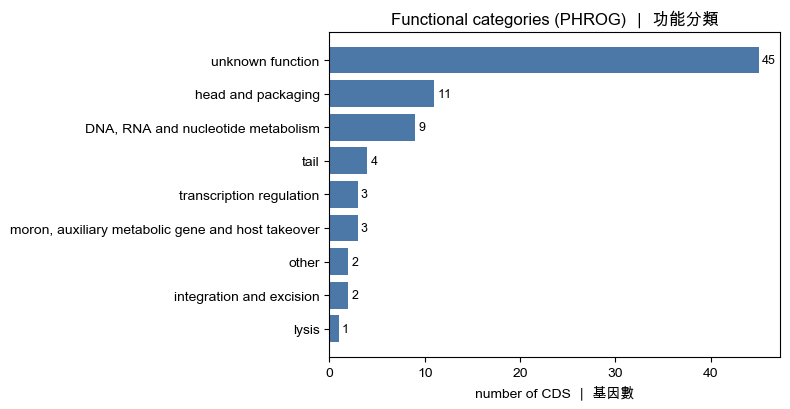

In [3]:
# --- viz 1: functional-category breakdown ---
cat_rows = func[~func["Description"].isin(["CDS","tRNAs","CRISPRs","tmRNAs",
              "VFDB_Virulence_Factors","CARD_AMR_Genes"])].copy()
cat_rows = cat_rows[cat_rows["Count"]>0].sort_values("Count")
fig, ax = plt.subplots(figsize=(8,4.2))
ax.barh(cat_rows["Description"], cat_rows["Count"], color="#4C78A8")
ax.set_xlabel("number of CDS ｜ 基因數"); ax.set_title("Functional categories (PHROG) ｜ 功能分類")
for i,(c) in enumerate(cat_rows["Count"]): ax.text(c+0.3, i, str(c), va="center", fontsize=9)
plt.tight_layout(); plt.savefig(OUT/"fig1_categories.png", dpi=130); plt.show()


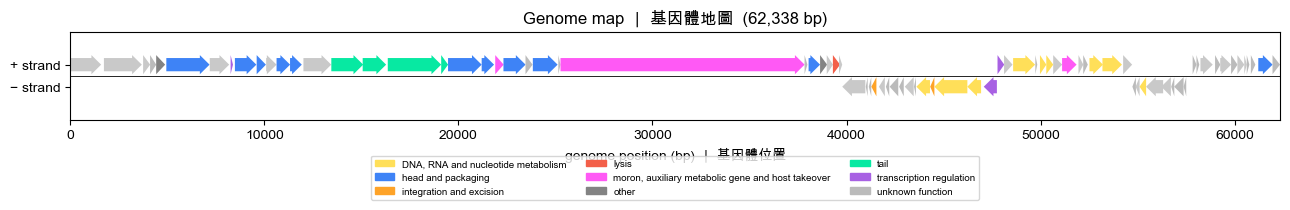

In [4]:
# --- viz 2: genome map (genes coloured by category) ---
# pharokka provides a per-CDS hex colour in the "color" column
palette = {}
def col_for(row):
    c = str(row.get("color","")).strip()
    return c if c.startswith("#") else "#BBBBBB"
fig, ax = plt.subplots(figsize=(13,2.6))
for _, r in cds.iterrows():
    x0, x1 = sorted([r["start"], r["stop"]]); y = 0.15 if r["strand"]=="+" else -0.15
    ax.add_patch(mpatches.FancyArrow(x0 if r["strand"]=="+" else x1, y,
        (x1-x0) if r["strand"]=="+" else -(x1-x0), 0, width=0.18, length_includes_head=True,
        head_width=0.26, head_length=min(500,(x1-x0)), color=col_for(r), linewidth=0))
    palette[r["category"]] = col_for(r)
ax.axhline(0, color="k", lw=0.6, zorder=0)
ax.set_xlim(0, L); ax.set_ylim(-0.6,0.6); ax.set_yticks([0.15,-0.15]); ax.set_yticklabels(["+ strand","− strand"])
ax.set_xlabel("genome position (bp) ｜ 基因體位置"); ax.set_title(f"Genome map ｜ 基因體地圖  ({L:,} bp)")
handles = [mpatches.Patch(color=c, label=k) for k,c in sorted(palette.items())]
ax.legend(handles=handles, ncol=3, fontsize=7, loc="upper center", bbox_to_anchor=(0.5,-0.35))
plt.tight_layout(); plt.savefig(OUT/"fig2_genome_map.png", dpi=130, bbox_inches="tight"); plt.show()


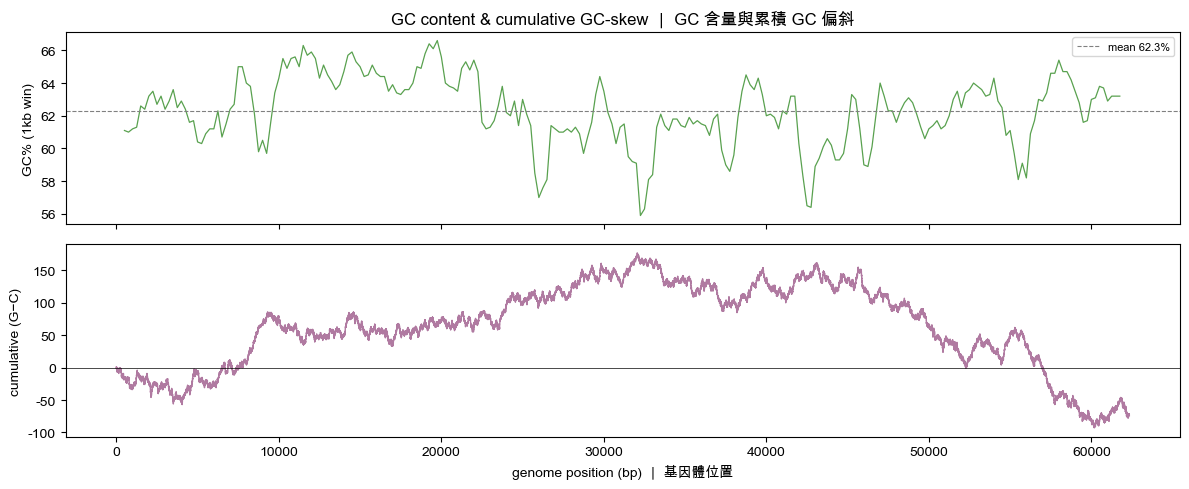

Cumulative GC-skew min/max positions can flag replication origin/terminus ｜ 累積 GC 偏斜的極值可提示複製起點/終點


In [5]:
# --- viz 3: GC content + cumulative GC-skew (helps locate replication origin/terminus) ---
win, step = 1000, 250
xs, gcw, skew = [], [], []
cum, running = [], 0.0
for i in range(0, L-win, step):
    w = genome[i:i+win]; g,c = w.count("G"), w.count("C")
    xs.append(i+win/2); gcw.append(100*(g+c)/win)
    s = (g-c)/(g+c) if (g+c) else 0; skew.append(s)
# cumulative skew over whole genome (per-base)
gc_skew_cum, tot = [], 0
for base in genome:
    if base=="G": tot+=1
    elif base=="C": tot-=1
    gc_skew_cum.append(tot)
fig, (a1,a2) = plt.subplots(2,1, figsize=(12,5), sharex=True)
a1.plot(xs, gcw, color="#59A14F", lw=0.9); a1.axhline(gc, color="grey", ls="--", lw=0.8, label=f"mean {gc:.1f}%")
a1.set_ylabel("GC% (1kb win)"); a1.legend(fontsize=8); a1.set_title("GC content & cumulative GC-skew ｜ GC 含量與累積 GC 偏斜")
a2.plot(range(L), gc_skew_cum, color="#B07AA1", lw=1.0)
a2.set_ylabel("cumulative (G−C)"); a2.set_xlabel("genome position (bp) ｜ 基因體位置")
a2.axhline(0, color="k", lw=0.5)
plt.tight_layout(); plt.savefig(OUT/"fig3_gc.png", dpi=130); plt.show()
print("Cumulative GC-skew min/max positions can flag replication origin/terminus ｜ 累積 GC 偏斜的極值可提示複製起點/終點")


## §2 · Most similar known phage (NCBI) ｜ 最相似的已知噬菌體（NCBI）

We search at **two levels**, and they answer different questions:

我們在**兩個層級**搜尋，各自回答不同問題：

1. **Nucleotide (megablast, genome vs `nt`)** — finds *close genomic relatives* (same species/near-identical
   phages). Fast to interpret, but for a **novel/divergent** phage the whole-genome nucleotide identity is
   often too low to hit anything meaningful.
   **核酸層級（全基因體 vs `nt`）**——找*基因體層級的近親*；但對新穎/分歧的噬菌體,全基因體核酸相似度常常低到搜不到東西。

2. **Protein (blastp of conserved marker genes: large terminase + major capsid vs `nr`)** — these
   structural/packaging proteins evolve **much more slowly** than the bulk genome and are the basis of
   **phage taxonomy** (ICTV classification leans on terminase/capsid phylogeny). So a protein search can
   reveal the **family/genus** even when the nucleotide search comes back empty. *This is why the
   protein-level hit is the more informative one for a novel phage.*
   **蛋白質層級（保守標記基因:大末端酶 + 主要殼體蛋白 vs `nr`）**——這些結構/包裝蛋白演化比整體基因體慢得多,是
   **噬菌體分類學**的依據（ICTV 分類主要看 terminase/capsid 親緣）。因此即使核酸搜尋一無所獲,蛋白質搜尋仍能揭示
   **科/屬**。*這就是為什麼對新穎噬菌體而言,蛋白質層級的結果更有價值。*

In [6]:
# --- what we already know LOCALLY (no upload needed) ---
# pharokka's mash vs INPHARED phage DB:
mash = pd.read_csv(PHK/"pharokka_top_hits_mash_inphared.tsv", sep="\t")
print("INPHARED mash top hit:", mash.iloc[0].to_dict().get("Description") or mash.iloc[0,1])
print("  -> pharokka found NO close INPHARED hit (mash distance > 0.2) => the genome is relatively NOVEL.")
print()
# nearest terminase relative, from dnaapler's terL search (local):
print("Nearest LARGE TERMINASE relative (from dnaapler terL search, local):")
print("  PHROG terminase phrog_2_MF042361_p3 | 97.7% coverage | 64.7% identity")
print("  (GenBank accession MF042361 is the closest catalogued terminase — a taxonomy hint,")
print("   distant at 64.7% id, consistent with a novel phage.)")


INPHARED mash top hit: nan
  -> pharokka found NO close INPHARED hit (mash distance > 0.2) => the genome is relatively NOVEL.

Nearest LARGE TERMINASE relative (from dnaapler terL search, local):
  PHROG terminase phrog_2_MF042361_p3 | 97.7% coverage | 64.7% identity
  (GenBank accession MF042361 is the closest catalogued terminase — a taxonomy hint,
   distant at 64.7% id, consistent with a novel phage.)


In [7]:
# --- §2a NUCLEOTIDE: megablast whole genome vs nt (UPLOADS the genome) ---
import json
NCBI_OUT = OUT/"ncbi_genome_megablast.json"
if ALLOW_NETWORK_UPLOAD:
    from Bio.Blast import NCBIWWW, NCBIXML
    print("Submitting 62 kb genome to NCBI megablast vs nt (can take several minutes)...")
    h = NCBIWWW.qblast("blastn", "nt", genome, megablast=True, hitlist_size=20, expect=1e-10)
    rec = NCBIXML.read(h)
    rows = [{"title": a.title[:90], "accession": a.accession, "length": a.length,
             "pct_identity": round(100*a.hsps[0].identities/a.hsps[0].align_length,1),
             "align_len": a.hsps[0].align_length, "evalue": a.hsps[0].expect} for a in rec.alignments]
    df = pd.DataFrame(rows); df.to_json(NCBI_OUT);
    print(df.head(15).to_string())
else:
    print("SKIPPED (ALLOW_NETWORK_UPLOAD=False). Set it True and run this cell yourself to megablast the genome vs NCBI nt.")
    print("跳過:此 cell 會把基因體上傳到 NCBI。請自行把 ALLOW_NETWORK_UPLOAD 設為 True 再執行。")


SKIPPED (ALLOW_NETWORK_UPLOAD=False). Set it True and run this cell yourself to megablast the genome vs NCBI nt.
跳過:此 cell 會把基因體上傳到 NCBI。請自行把 ALLOW_NETWORK_UPLOAD 設為 True 再執行。


In [8]:
# --- §2b PROTEIN: blastp large terminase + major capsid vs nr (UPLOADS proteins; taxonomy signal) ---
# pull the two marker proteins from the pharokka CDS predictions
prot = {r.id.split()[0]: str(r.seq) for r in SeqIO.parse(str(PHK/"phanotate.faa"), "fasta")}
markers = {}
for _, r in cds.iterrows():
    a = str(r.get("annot","")).lower()
    if "terminase" in a and "large" in a: markers.setdefault("large_terminase", r["gene"])
    if "major head" in a or "major capsid" in a: markers.setdefault("major_capsid", r["gene"])
# fallback: terminase (any) / portal
if "large_terminase" not in markers:
    for _, r in cds.iterrows():
        if "terminase" in str(r.get("annot","")).lower(): markers["terminase"]=r["gene"]; break
print("marker proteins for taxonomy blastp:", markers)
if ALLOW_NETWORK_UPLOAD:
    from Bio.Blast import NCBIWWW, NCBIXML
    allrows=[]
    for label, gene in markers.items():
        seq = prot.get(gene)
        if not seq: continue
        print(f"  blastp {label} ({gene}, {len(seq)}aa) vs nr ...")
        h = NCBIWWW.qblast("blastp","nr",seq,hitlist_size=10,expect=1e-5)
        rec = NCBIXML.read(h)
        for a in rec.alignments[:10]:
            hsp=a.hsps[0]
            allrows.append({"marker":label,"title":a.title[:80],"accession":a.accession,
                "pct_identity":round(100*hsp.identities/hsp.align_length,1),"evalue":hsp.expect})
    dfp=pd.DataFrame(allrows); dfp.to_csv(OUT/"ncbi_marker_blastp.tsv",sep="\t",index=False)
    print(dfp.to_string())
else:
    print("SKIPPED (ALLOW_NETWORK_UPLOAD=False). Flip the flag and run to place the phage taxonomically via marker proteins.")


marker proteins for taxonomy blastp: {'major_capsid': 'FHABPWTM_CDS_0009', 'terminase': 'FHABPWTM_CDS_0079'}
SKIPPED (ALLOW_NETWORK_UPLOAD=False). Flip the flag and run to place the phage taxonomically via marker proteins.


## §3 · RBPs in this genome + PhaRBP check ｜ 本基因體的 RBP + PhaRBP 查詢

The final section does two linked things: **(a)** identify this genome's receptor-binding proteins (RBPs)
and their variable region, then **(b)** check whether those RBPs are catalogued in **PhaRBP**.
最後一節做兩件相關的事:**(a)** 找出本基因體的受體結合蛋白（RBP）與其變異區,**(b)** 到 **PhaRBP** 查詢這些 RBP 是否已被收錄。

### §3a · Finding the RBPs ｜ 找出 RBP

The RBPs sit in the **tail module** (CDS_0014–0020): two **tailspikes** + a large **tail protein** + a small
**tail fiber**. Each has a **conserved N-terminal virion-attachment domain** and a **variable C-terminal
receptor-binding domain (RBD)** — the RBD is "the variable region". The tailspikes have a fibrous
**β-helix-depolymerase** amino-acid signature → the likely receptor is the host **LPS O-antigen**.
RBP 位於**尾部模組**（CDS_0014–0020）:兩個 **tailspike** + 一個大 **tail protein** + 一個小 **tail fiber**。
每個都有**保守的 N 端顆粒附著域**與**變異的 C 端受體結合域（RBD）**——RBD 就是「變異區」。tailspike 帶纖維狀
**β-helix depolymerase** 的胺基酸特徵 → 受體很可能是宿主的 **LPS O-antigen**。

In [9]:
# tail module CDS
tail = cds[cds["category"]=="tail"][["gene","start","stop","strand","annot"]].copy()
tail["length_aa"] = ((tail["stop"]-tail["start"]).abs()+1)//3 - 1
print("Tail / RBP module:");
tail


Tail / RBP module:


,gene,start,stop,strand,annot,length_aa
14,FHABPWTM_CDS_0015,13449,15092,+,tail spike protein,547
15,FHABPWTM_CDS_0016,15065,16273,+,tail spike protein,402
16,FHABPWTM_CDS_0017,16358,19111,+,tail protein,917
17,FHABPWTM_CDS_0018,19111,19467,+,tail fiber protein,118


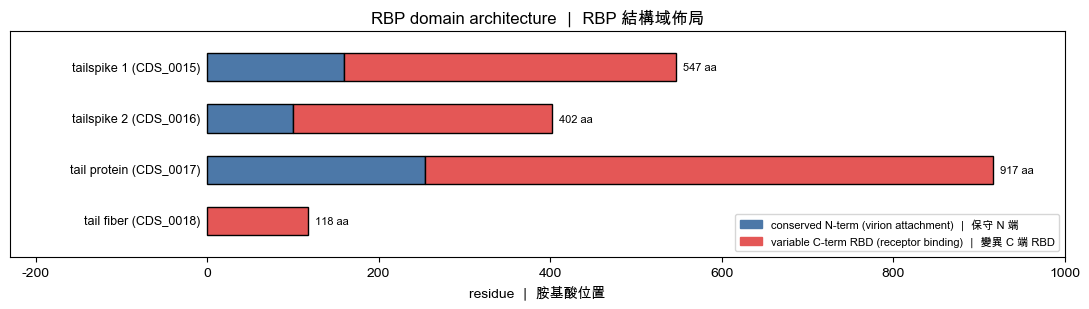

In [10]:
# --- viz 4: RBP domain architecture (conserved N-term vs variable C-term RBD) ---
def aalen(p):
    s=next(SeqIO.parse(str(RBPS/p),"fasta")); return len(str(s.seq))
rbp_defs = [  # (label, file, aa, conserved_N_end)  -- boundaries approx (refine by structure)
 ("tailspike 1 (CDS_0015)","CDS_0015_tailspike1.faa",547,160),
 ("tailspike 2 (CDS_0016)","CDS_0016_tailspike2.faa",402,100),
 ("tail protein (CDS_0017)","CDS_0017_tailprotein.faa",917,254),
 ("tail fiber (CDS_0018)","CDS_0018_tailfiber.faa",118,0)]
fig, ax = plt.subplots(figsize=(11,3.2))
for i,(lab,f,aa,ncut) in enumerate(rbp_defs):
    y=len(rbp_defs)-i
    if ncut>0: ax.barh(y, ncut, color="#4C78A8", edgecolor="k", height=0.55)
    ax.barh(y, aa-ncut, left=ncut, color="#E45756", edgecolor="k", height=0.55)
    ax.text(aa+8, y, f"{aa} aa", va="center", fontsize=8)
    ax.text(-8, y, lab, va="center", ha="right", fontsize=9)
ax.set_yticks([]); ax.set_xlim(-230, 1000); ax.set_ylim(0.3,len(rbp_defs)+0.7)
ax.set_xlabel("residue ｜ 胺基酸位置")
ax.set_title("RBP domain architecture ｜ RBP 結構域佈局")
ax.legend(handles=[mpatches.Patch(color="#4C78A8",label="conserved N-term (virion attachment) ｜ 保守 N 端"),
                   mpatches.Patch(color="#E45756",label="variable C-term RBD (receptor binding) ｜ 變異 C 端 RBD")],
          fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(OUT/"fig4_rbp_domains.png", dpi=130, bbox_inches="tight"); plt.show()


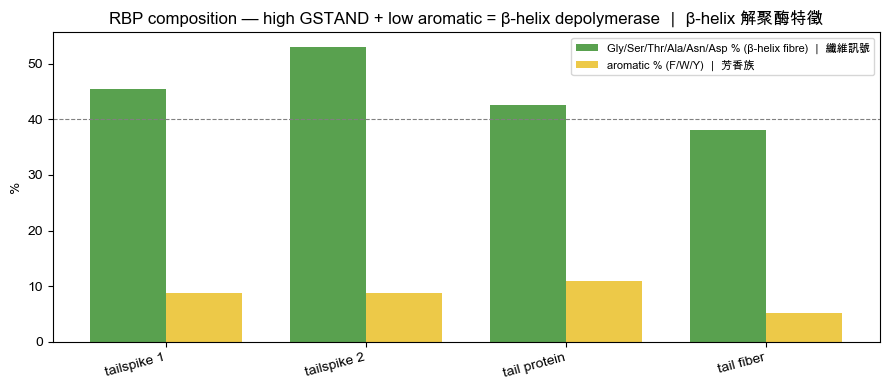

High GSTAND (~40-53%) + low aromatic across all RBPs => fibrous β-helix fold typical of LPS-degrading tailspikes.


In [11]:
# --- viz 5: RBP amino-acid composition (β-helix-depolymerase fibre signature) ---
def comp(seq):
    n=len(seq); g=sum(seq.count(a) for a in "GSTAND")/n; ar=sum(seq.count(a) for a in "FWY")/n
    return 100*g, 100*ar
labels, gst, aro = [], [], []
for lab,f,aa,ncut in rbp_defs:
    s=str(next(SeqIO.parse(str(RBPS/f),"fasta")).seq)
    g,a=comp(s); labels.append(lab.split("(")[0].strip()); gst.append(g); aro.append(a)
x=np.arange(len(labels)); w=0.38
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(x-w/2, gst, w, label="Gly/Ser/Thr/Ala/Asn/Asp % (β-helix fibre) ｜ 纖維訊號", color="#59A14F")
ax.bar(x+w/2, aro, w, label="aromatic % (F/W/Y) ｜ 芳香族", color="#EDC948")
ax.axhline(40, color="grey", ls="--", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15, ha="right"); ax.set_ylabel("%")
ax.set_title("RBP composition — high GSTAND + low aromatic = β-helix depolymerase ｜ β-helix 解聚酶特徵")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT/"fig5_rbp_composition.png", dpi=130); plt.show()
print("High GSTAND (~40-53%) + low aromatic across all RBPs => fibrous β-helix fold typical of LPS-degrading tailspikes.")


### §3b · Is it in PhaRBP? ｜ PhaRBP 中有沒有它？

[**PhaRBP**](https://pharbp.ugent.be) (UGent / Boeckaerts group) is a **phage-RBP** database: each entry maps
an RBP → its phage → its host bacterium (there is **no receptor field**). So "is this phage in PhaRBP?" is
answered at the **RBP level** — do our RBPs match catalogued ones, and if so, which known phage/host?
PhaRBP 是一個**噬菌體 RBP** 資料庫:每筆記錄是 RBP → 噬菌體 → 宿主（**沒有受體欄位**）。所以「這個噬菌體在
PhaRBP 裡嗎」要在 **RBP 層級**回答——我們的 RBP 是否比對到已收錄的,若有,對應哪個已知噬菌體/宿主？

- **Track A (download, no upload):** pull all *Pseudomonas*-host RBPs catalogued in PhaRBP for context.
  **Track A（下載,不上傳）:** 取出 PhaRBP 中所有 *Pseudomonas* 宿主的 RBP 作為背景。
- **Track B (upload — you run it):** BLASTP each of our 4 RBPs against PhaRBP to see catalogued homologs.
  **Track B（上傳——請自行執行）:** 把我們的 4 個 RBP 對 PhaRBP 做 BLASTP,看有無已收錄的同源蛋白。

In [12]:
# --- Track A: PhaRBP Pseudomonas RBPs (CSV export = DOWNLOAD, safe) ---
import requests
r = requests.get("https://pharbp.ugent.be/export/results/",
                 params={"host_genus":"Pseudomonas","unique":"1","download":"csv"},
                 headers={"User-Agent":"iGEM6317-pharbp-client/1.0"}, timeout=120)
r.raise_for_status()
pa = pd.read_csv(io.StringIO(r.text))
pa.to_csv(OUT/"pharbp_pseudomonas_rbps.csv", index=False)
print(f"PhaRBP Pseudomonas RBP records: {len(pa)}  | phages: {pa['Phage Name'].nunique()}  | hosts: {pa['Host Name(s)'].nunique()}")
print("\nTop phages by #RBPs:")
print(pa["Phage Name"].value_counts().head(8).to_string())


PhaRBP Pseudomonas RBP records: 198  | phages: 60  | hosts: 21

Top phages by #RBPs:
Phage Name
Pseudomonas phage tabernarius      8
Pseudomonas phage ventosus         7
Pseudomonas phage D6               7
Pseudomonas phage PsgM04F          7
Pseudomonas phage Alpheus          7
Pseudomonas phage PsgM02F          7
Pseudomonas phage vB_PaeM_M12PA    6
Pseudomonas phage nickie           6


In [13]:
# --- Track B: BLASTP our RBPs vs PhaRBP (UPLOADS our RBPs) -- verified API from code/0701_pharbp_query ---
import requests, time
BASE="https://pharbp.ugent.be"
rbp_seqs = {r.id: str(r.seq) for r in SeqIO.parse(str(RBPS/"rbps_all.faa"), "fasta")}
if ALLOW_NETWORK_UPLOAD:
    s=requests.Session(); s.headers["User-Agent"]="iGEM6317-pharbp-client/1.0"
    s.get(f"{BASE}/blastp/", timeout=30); tok=s.cookies.get("csrftoken")
    hdr={"X-CSRFToken":tok,"Referer":f"{BASE}/blastp/"}
    rows=[]
    for name,seq in rbp_seqs.items():
        up=s.post(f"{BASE}/api/blastp/upload/", data={"sequence":seq}, headers=hdr, timeout=120)
        qid=up.json().get("query_id")
        hits=s.get(f"{BASE}/api/blastp/results/{qid}/", timeout=60).json().get("results",[])
        if not hits: rows.append({"rbp":name,"hit":"(none)"})
        for h in hits[:5]:
            rows.append({"rbp":name,"pct_id":h.get("percent_identity"),"phage":h.get("phage_name"),
                         "host":"; ".join(h.get("host_names") or []),"evalue":h.get("evalue"),
                         "protein_id":h.get("protein_id")})
        time.sleep(0.5)
    dfb=pd.DataFrame(rows); dfb.to_csv(OUT/"pharbp_our_rbps_hits.tsv", sep="\t", index=False)
    print(dfb.to_string())
else:
    print("SKIPPED (ALLOW_NETWORK_UPLOAD=False). Set it True and run to BLASTP our RBPs against PhaRBP.")
    print(f"({len(rbp_seqs)} RBPs ready: {', '.join(rbp_seqs)})")
    print("跳過:此 cell 會把我們的 RBP 上傳到 PhaRBP。請自行改旗標再執行。")


SKIPPED (ALLOW_NETWORK_UPLOAD=False). Set it True and run to BLASTP our RBPs against PhaRBP.
(7 RBPs ready: FHABPWTM_CDS_0014_hypo_preTail, FHABPWTM_CDS_0015_tailspike1, FHABPWTM_CDS_0016_tailspike2, FHABPWTM_CDS_0017_tailprotein, FHABPWTM_CDS_0018_tailfiber, FHABPWTM_CDS_0019_intvirion, FHABPWTM_CDS_0020_virionstruct)
跳過:此 cell 會把我們的 RBP 上傳到 PhaRBP。請自行改旗標再執行。


### Interpretation ｜ 判讀

- **Novelty:** pharokka's INPHARED mash returned no close hit and the nearest terminase relative is only
  ~64.7% identical → this is a **relatively novel** phage; the protein-level NCBI search (§2b) is the best
  way to place it taxonomically. Prior work (`0701_pharbp_query`) found our metagenome RBPs were largely
  novel vs PhaRBP, with only distant matches to *Pseudomonas* phages Y5/Phabio/Y12 — expect the same here.
- **Receptor:** PhaRBP has no receptor field, so the RBP→receptor pairing must come from our own structural
  fold screen (`code/0708_rbp_analysis/fold/`, run on Laguna), not this database.
- **新穎性:** INPHARED mash 無近似命中、最近的 terminase 也只有 ~64.7% → 相對新穎;§2b 蛋白質層級搜尋最能定分類。
- **受體:** PhaRBP 沒有受體欄位,RBP↔受體配對要靠我們自己的結構摺疊篩選（Laguna),不是這個資料庫。

**Full RBP reasoning ｜ 完整 RBP 推論:** [`code/0708_rbp_analysis/RBP_variable_region_analysis.md`](../0708_rbp_analysis/RBP_variable_region_analysis.md)

---
*Log ｜ 紀錄: 2026-07-08 — created. Local analysis + PhaRBP CSV run here; NCBI/PhaRBP upload cells are
guarded (`ALLOW_NETWORK_UPLOAD`) for the user to run.*